In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

In [19]:
# Load CSV with two header rows
df = pd.read_csv("../Datasets/GPS_Dataset_3D_8_Channels_Authentic_and_Simulated.csv", header=[0, 1])

# List of variables/features to plot (excluding 'Output' for per-channel plots)
features = [
    "PRN", "Carrier_Doppler_hz", "Pseudorange_m", "RX_time", "TOW_at_current_symbol_s",
    "Carrier_phase_cycles", "EC", "LC", "PC", "PIP", "PQP", "TCD", "CN0"
]

In [20]:
print(df.columns.tolist())

[('PRN', 'ch0'), ('Unnamed: 1_level_0', 'ch1'), ('Unnamed: 2_level_0', 'ch2'), ('Unnamed: 3_level_0', 'ch3'), ('Unnamed: 4_level_0', 'ch4'), ('Unnamed: 5_level_0', 'ch5'), ('Unnamed: 6_level_0', 'ch6'), ('Unnamed: 7_level_0', 'ch7'), ('Carrier_Doppler_hz', 'ch0'), ('Unnamed: 9_level_0', 'ch1'), ('Unnamed: 10_level_0', 'ch2'), ('Unnamed: 11_level_0', 'ch3'), ('Unnamed: 12_level_0', 'ch4'), ('Unnamed: 13_level_0', 'ch5'), ('Unnamed: 14_level_0', 'ch6'), ('Unnamed: 15_level_0', 'ch7'), ('Pseudorange_m', 'ch0'), ('Unnamed: 17_level_0', 'ch1'), ('Unnamed: 18_level_0', 'ch2'), ('Unnamed: 19_level_0', 'ch3'), ('Unnamed: 20_level_0', 'ch4'), ('Unnamed: 21_level_0', 'ch5'), ('Unnamed: 22_level_0', 'ch6'), ('Unnamed: 23_level_0', 'ch7'), ('RX_time', 'ch0'), ('Unnamed: 25_level_0', 'ch1'), ('Unnamed: 26_level_0', 'ch2'), ('Unnamed: 27_level_0', 'ch3'), ('Unnamed: 28_level_0', 'ch4'), ('Unnamed: 29_level_0', 'ch5'), ('Unnamed: 30_level_0', 'ch6'), ('Unnamed: 31_level_0', 'ch7'), ('TOW_at_current_s

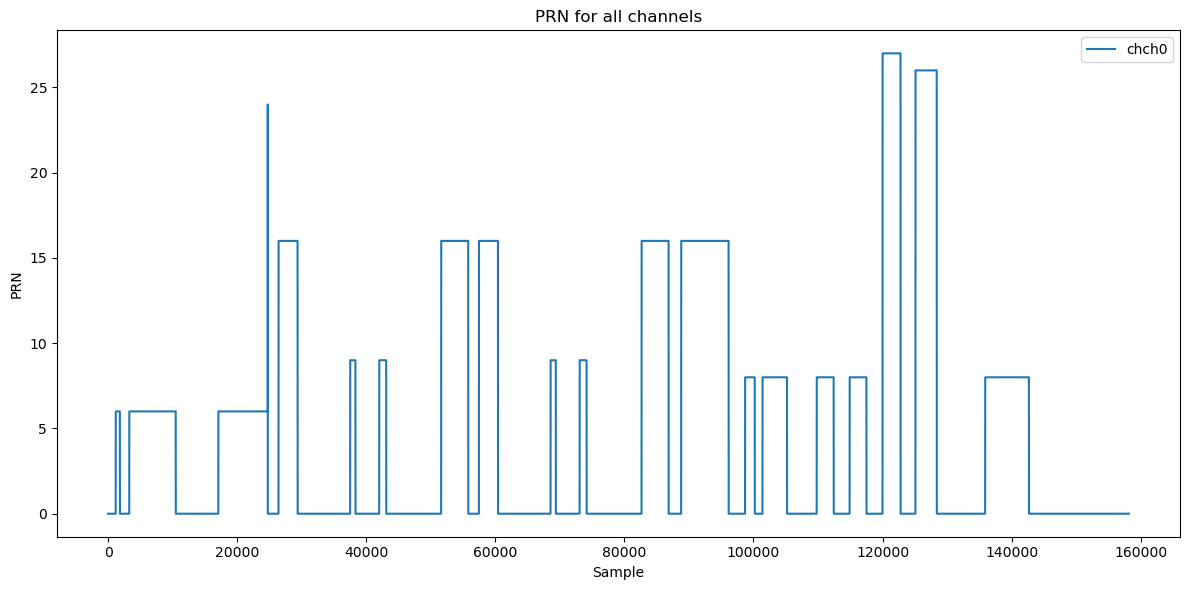

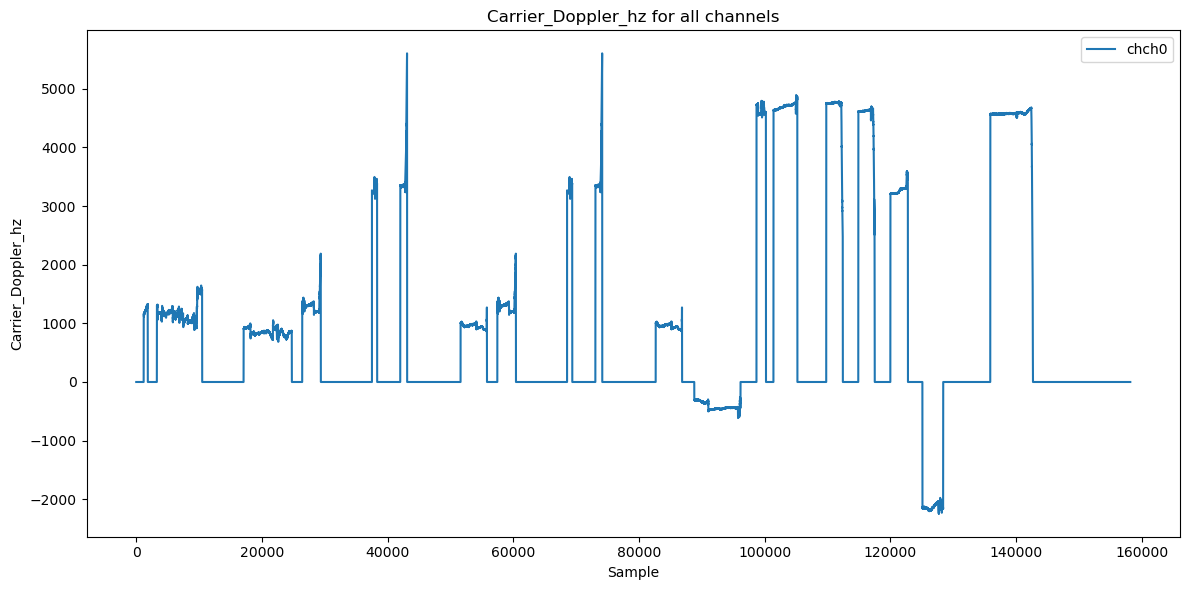

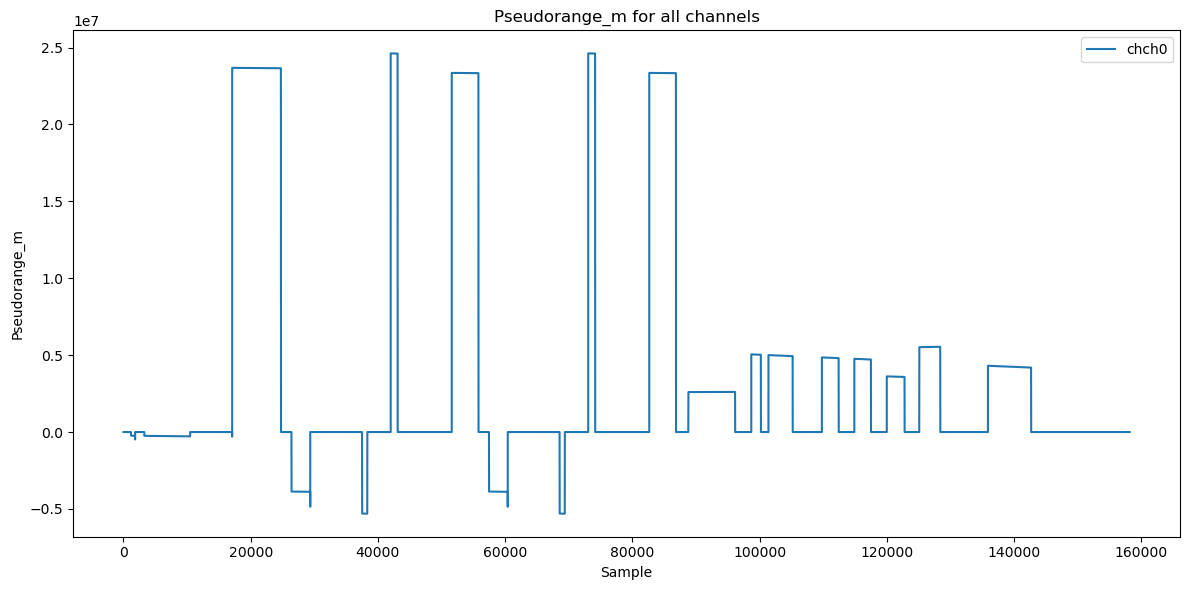

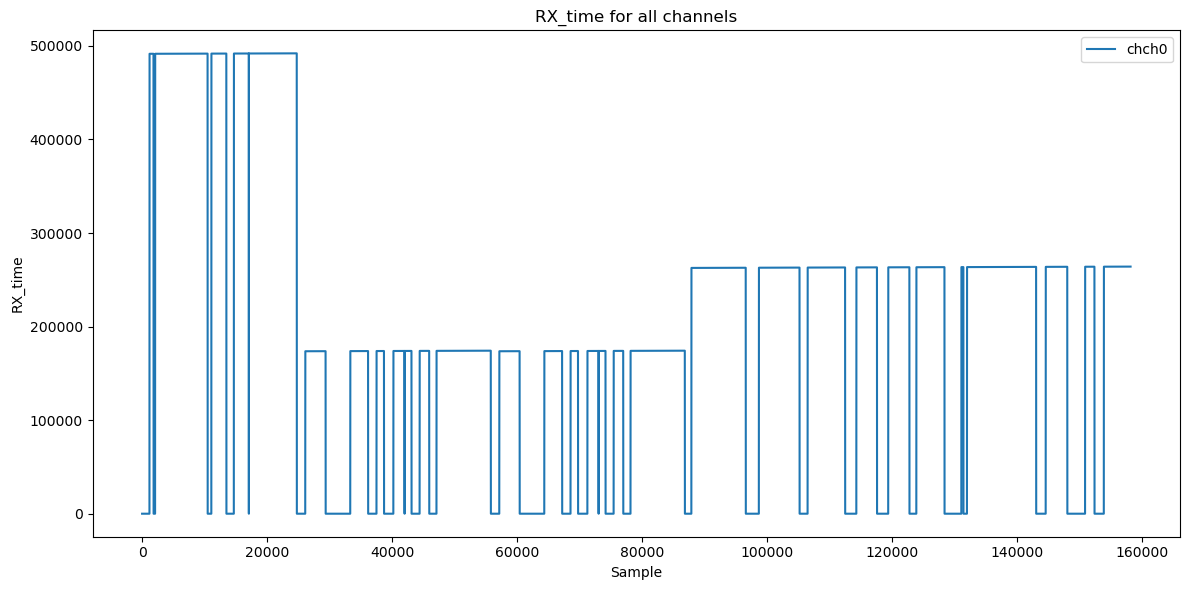

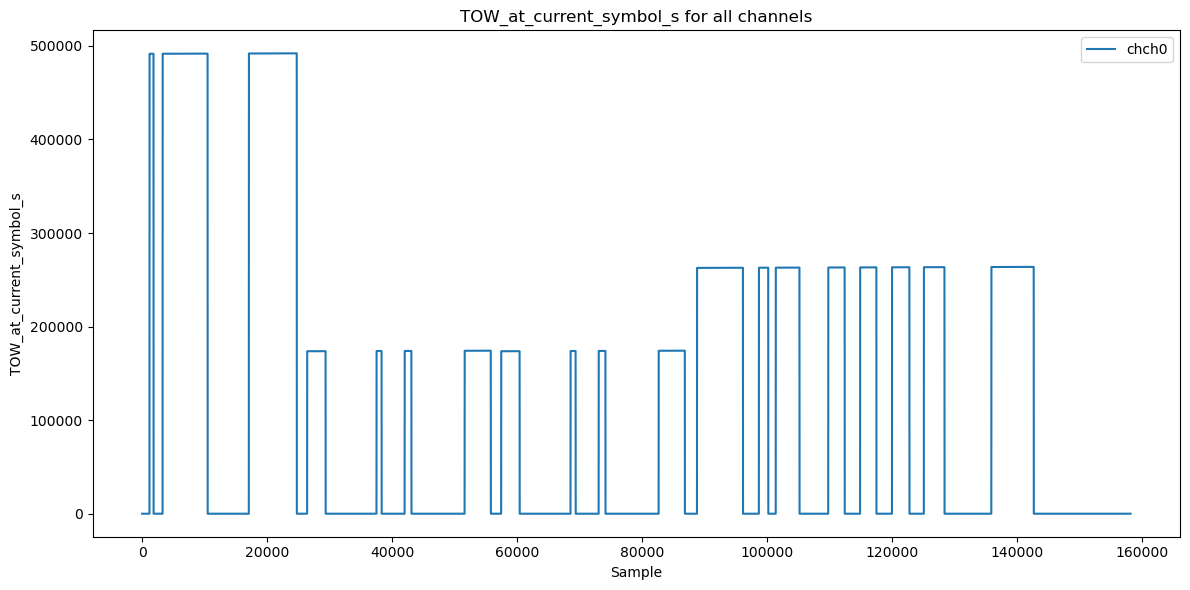

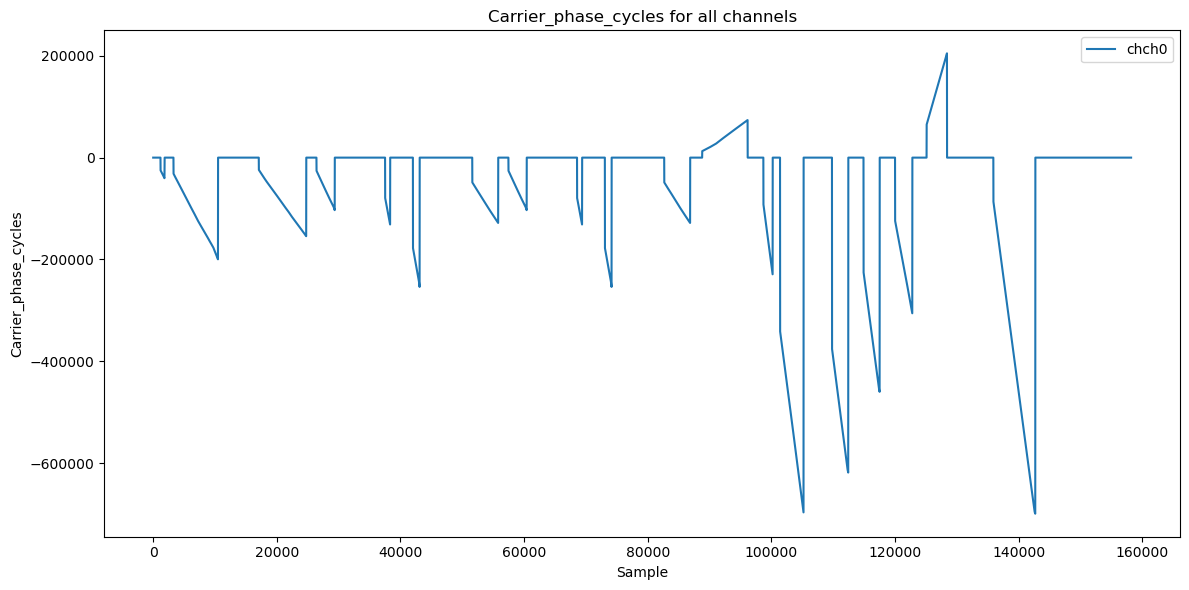

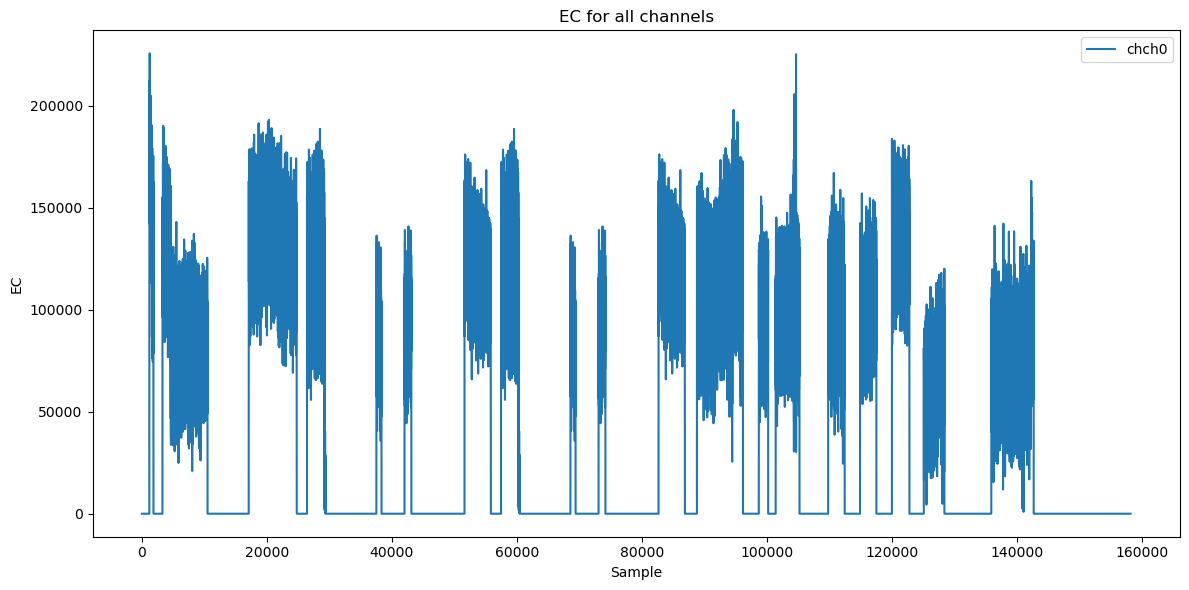

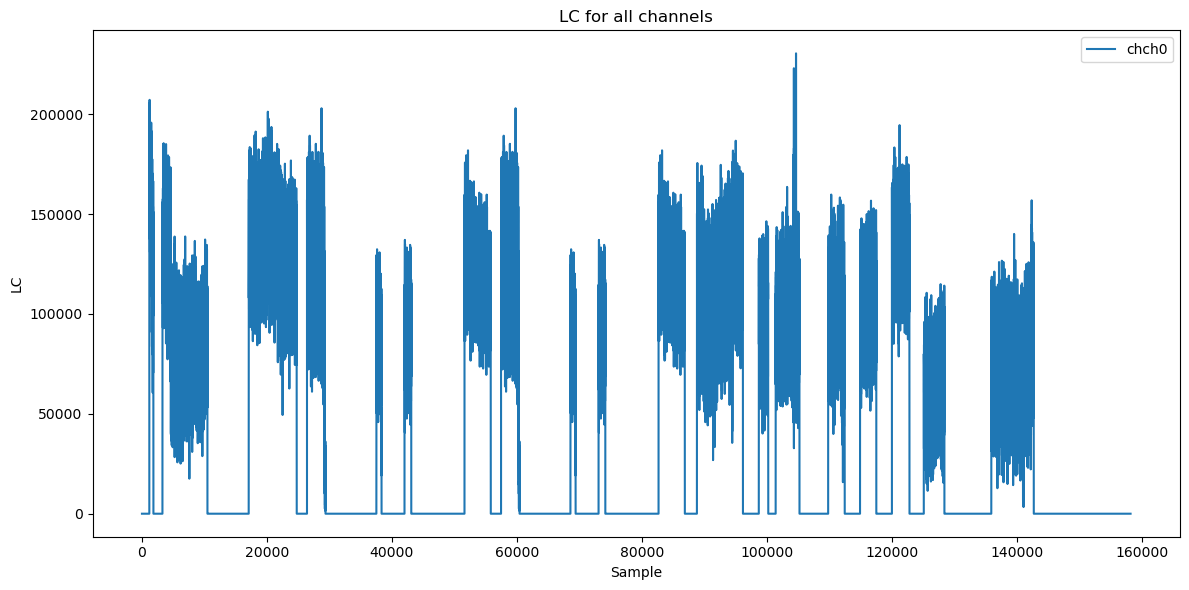

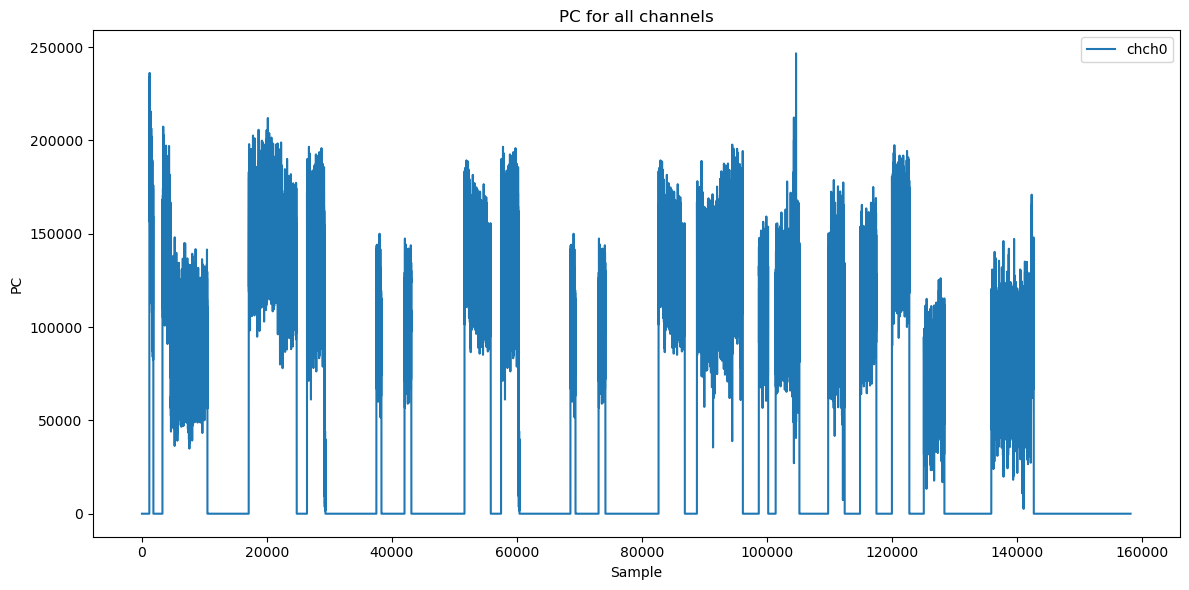

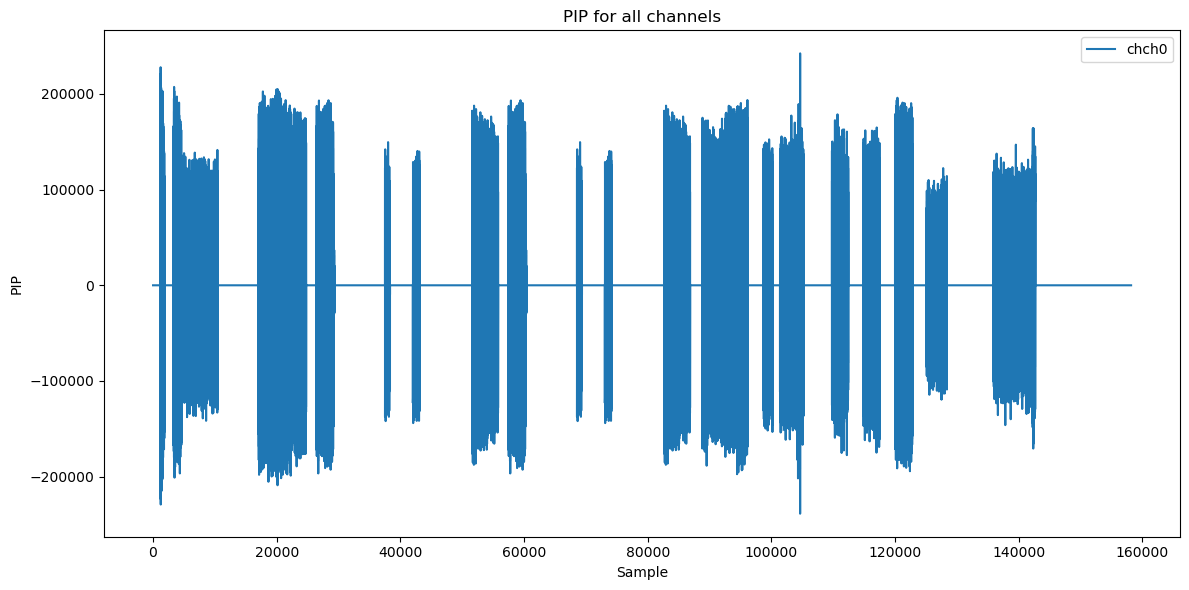

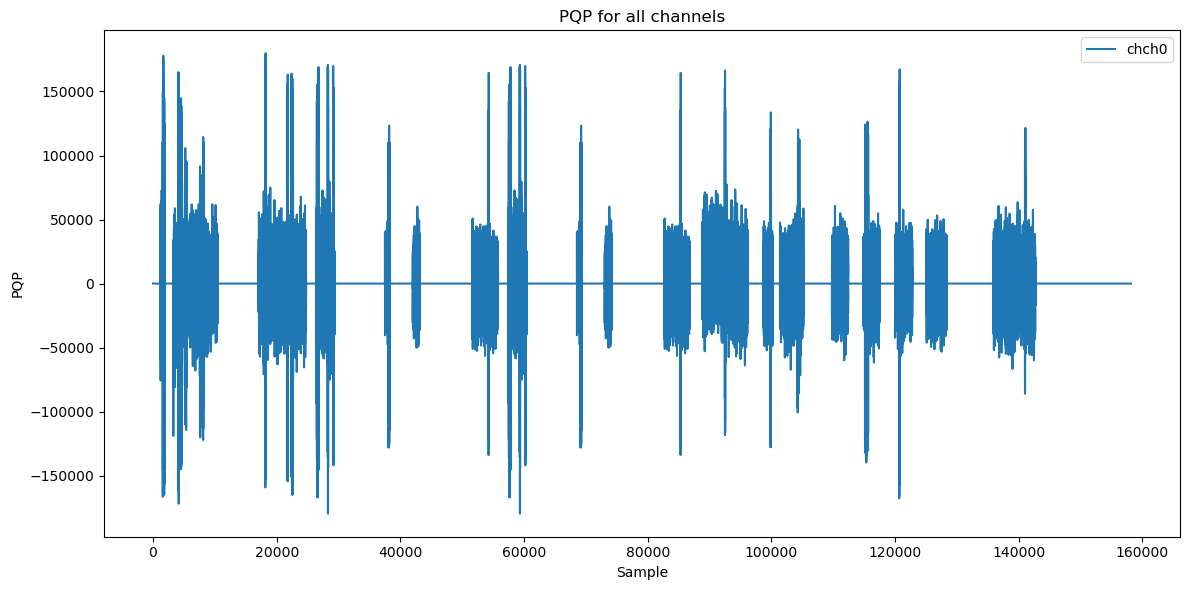

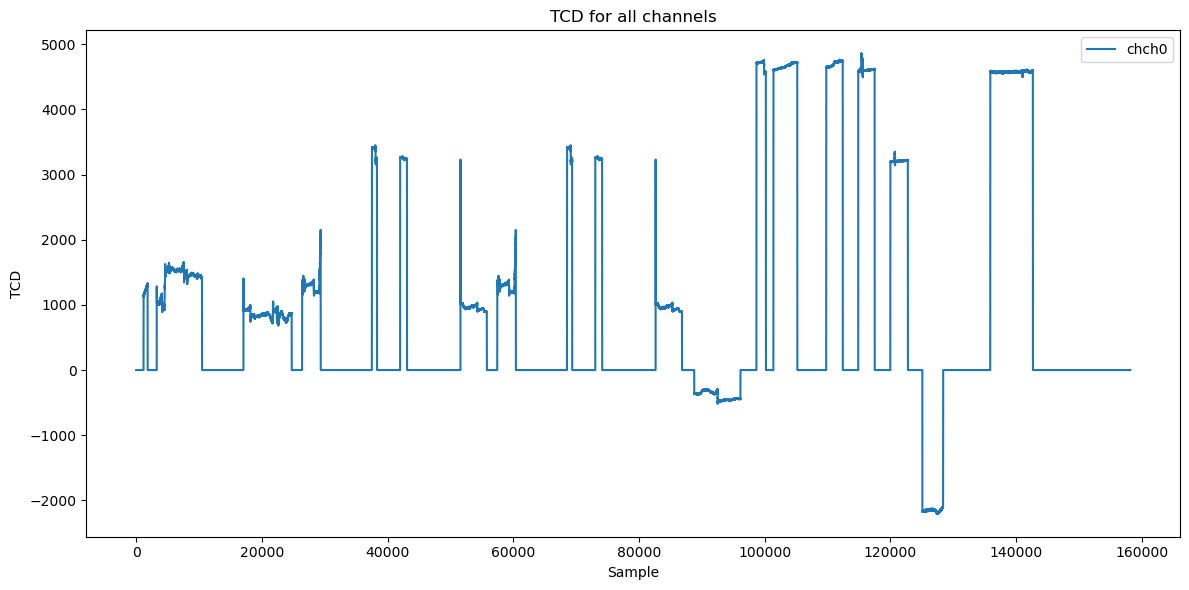

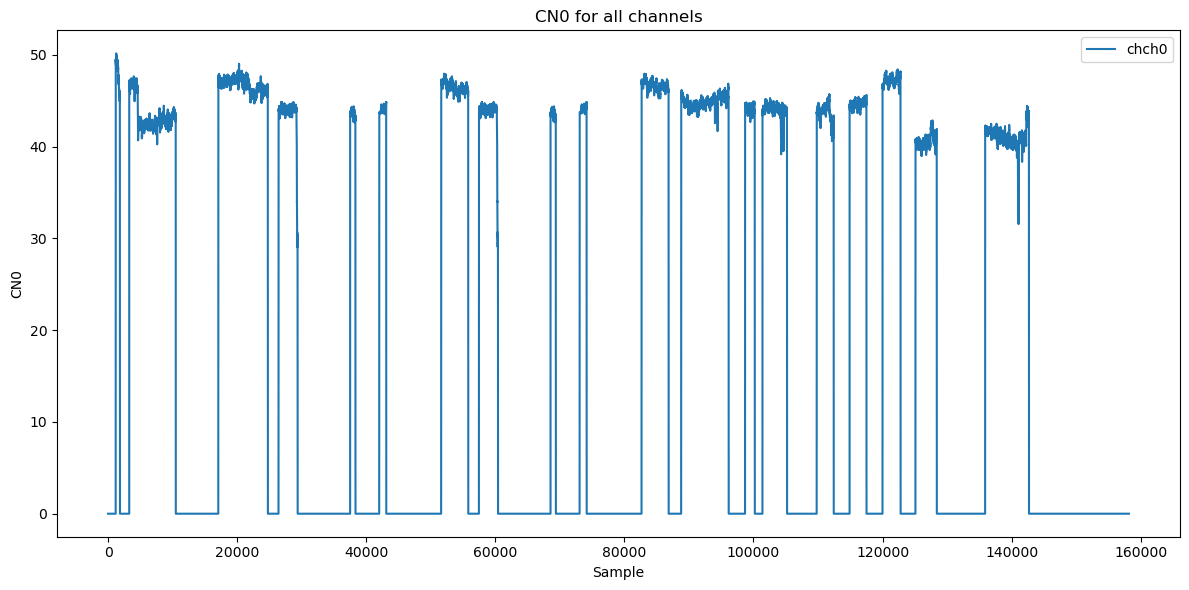

In [21]:
for features in features:
    # Find all channel columns for this variable
    channels = [col[1] for col in df.columns if col[0] == features]
    if not channels:
        continue  # Skip if none found

    plt.figure(figsize=(12, 6))
    for ch in channels:
        series = df[(features, ch)]
        if pd.api.types.is_numeric_dtype(series):
            plt.plot(series, label=f"ch{ch}")
    plt.xlabel("Sample")
    plt.ylabel(features)
    plt.title(f"{features} for all channels")
    plt.legend()
    plt.tight_layout()
    plt.show()

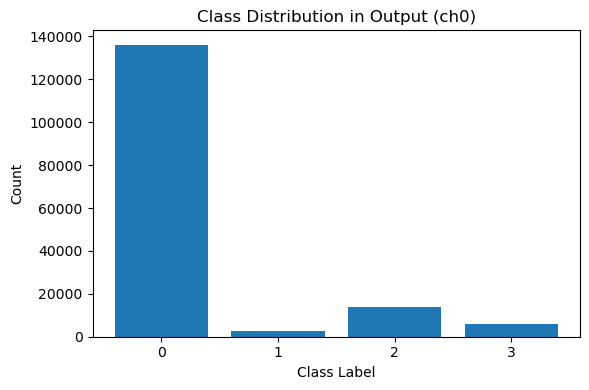

In [22]:
output_series = df[('Output', 'ch0')]

output_series = output_series.astype(str).str.strip()
output_series = output_series.str.extract(r'(\d+)')[0]
output_series = pd.to_numeric(output_series, errors='coerce')

vc = output_series.value_counts().sort_index()
vc.index = vc.index.astype(int)

plt.figure(figsize=(6, 4))
plt.bar(vc.index, vc.values)
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.title("Class Distribution in Output (ch0)")
plt.xticks(vc.index)
plt.tight_layout()
plt.show()

# 0 = authentic GPS signal,
# 1 = simple spoofing attack,
# 2 = intermediate spoofing attack,
# 3 = advanced spoofing attack.
# The class distribution is highly imbalanced, with class 0 (authentic) dominating the dataset

In [23]:
# Label column
y = df[('Output', 'ch0')].astype(str).str.strip().str.extract(r'(\d+)')[0]
y = pd.to_numeric(y, errors='coerce')

# Drop only the Output ch0 column
X = df.drop(('Output', 'ch0'), axis=1)

# K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    print(f"\nFold {fold}:")
    print("Train class distribution:")
    print(y_train.value_counts(normalize=True).sort_index())
    print("Test class distribution:")
    print(y_test.value_counts(normalize=True).sort_index())


Fold 1:
Train class distribution:
0
0    0.859942
1    0.015805
2    0.086321
3    0.037933
Name: proportion, dtype: float64
Test class distribution:
0
0    0.859965
1    0.015805
2    0.086297
3    0.037933
Name: proportion, dtype: float64

Fold 2:
Train class distribution:
0
0    0.859942
1    0.015805
2    0.086321
3    0.037933
Name: proportion, dtype: float64
Test class distribution:
0
0    0.859965
1    0.015805
2    0.086297
3    0.037933
Name: proportion, dtype: float64

Fold 3:
Train class distribution:
0
0    0.859949
1    0.015805
2    0.086313
3    0.037933
Name: proportion, dtype: float64
Test class distribution:
0
0    0.859934
1    0.015805
2    0.086328
3    0.037933
Name: proportion, dtype: float64

Fold 4:
Train class distribution:
0
0    0.859949
1    0.015805
2    0.086313
3    0.037933
Name: proportion, dtype: float64
Test class distribution:
0
0    0.859934
1    0.015805
2    0.086328
3    0.037933
Name: proportion, dtype: float64

Fold 5:
Train class distributio